# Lab 3 | TV04 - XGBoost cơ sở & Feature Importance

**Phụ trách: Võ Huy Hoàng (TV04)** | Hạn bàn giao: 31/10/2026 | Reviewer: TV05 (Ngọc Ánh)

---

### Mục tiêu & Nhiệm vụ thực hiện:
1. **Huấn luyện mô hình XGBoost cơ sở (Bước 5 của đề bài):** Sử dụng factory chuẩn `make_model("xgboost")`, huấn luyện chỉ trên tập `train` (96.844 mẫu từ `2004-10-08 01:00:00` đến `2015-10-27 04:00:00`), ghi nhận đầy đủ siêu tham số, seed ngẫu nhiên và thời gian chạy.
2. **Soát Overfitting bằng Cross-Validation:** Kiểm định mô hình thông qua `TimeSeriesSplit` (3 folds, mỗi fold validation dài 672 giờ ~ 4 tuần) hoàn toàn bên trong tập train; tuyệt đối không dùng tập test để chọn siêu tham số.
3. **Thực thi Hợp đồng Dự đoán (Prediction Contract - Bước 6):** Dự báo trên tập kiểm tra độc lập `test` (24.257 mẫu từ `2015-10-27 05:00:00` đến `2018-08-03 00:00:00`), tính toán các thước đo lỗi chuẩn hóa (`MAE`, `RMSE`, `MAPE`), xuất file dự báo và metrics theo đúng hợp đồng bàn giao.
4. **Phân tích Độ quan trọng Đặc trưng (Feature Importance - Bước 7):** Trích xuất tiêu chí `gain` cho 28 đặc trưng (24 lags và 4 thống kê trượt), biểu diễn Top 15 đặc trưng, phân tích hiện tượng tương quan giữa các lags và giới hạn diễn giải nhân quả.
5. **Trả lời Câu hỏi 3 của Đề bài & Bàn giao:** Xây dựng hệ thống luận điểm so sánh khoa học: *"Khi nào XGBoost phù hợp hơn ARIMA?"* và đóng gói sản phẩm bàn giao cho TV05, TV06 và Leader TV01.

In [1]:
from pathlib import Path
import json
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "configs/experiment.json").is_file())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from lab3.data import load_prepared, split_supervised
from lab3.features import make_supervised, xy
from lab3.evaluation import regression_metrics
from lab3.modeling import make_model

cfg = json.loads((ROOT / "configs/experiment.json").read_text(encoding="utf-8"))
frame, quality = load_prepared(ROOT / cfg["prepared_dataset_dir"], raw_path=ROOT / cfg["dataset_path"])
supervised = make_supervised(frame, p=cfg["default_p"],
    rolling_windows=tuple(cfg["rolling_windows"]), warmup=cfg["warmup_hours"])
train, test = split_supervised(supervised, cfg["test_start"])
X_train, y_train = xy(train)
X_test, y_test = xy(test)

print({"raw_rows": quality["raw_rows"], "train_rows": len(train),
       "test_rows": len(test), "test_start": cfg["test_start"],
       "n_features": X_train.shape[1], "features": list(X_train.columns[:6]) + ["..."]})

{'raw_rows': 121273, 'train_rows': 96844, 'test_rows': 24257, 'test_start': '2015-10-27 05:00:00', 'n_features': 28, 'features': ['lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5', 'lag_6', '...']}


## 1. Huấn luyện Mô hình XGBoost Cơ sở (Bước 5)

Mô hình XGBoost cơ sở được khởi tạo từ hàm factory `make_model("xgboost", seed=42)` định nghĩa trong `src/lab3/modeling.py`. Cấu hình cơ sở bao gồm:
- `n_estimators = 200`: Số lượng cây quyết định vừa phải để đảm bảo tốc độ huấn luyện nhanh và kiểm soát sai số.
- `max_depth = 4`: Độ sâu cây nông nhằm giới hạn độ phức tạp và ngăn chặn overfit.
- `learning_rate = 0.05`: Tốc độ học nhỏ giúp mô hình hội tụ ổn định và tạo độ tổng quát hóa cao.
- `tree_method = 'hist'`: Thuật toán chia nhánh dựa trên histogram giúp tăng tốc độ huấn luyện trên tập dữ liệu lớn gần 100.000 dòng.
- `objective = 'reg:squarederror'`: Tối ưu hóa hàm tổn thất sai số bình phương trung bình (MSE).
- `importance_type = 'gain'`: Đo lường mức cải thiện hàm mục tiêu trung bình tại các nút phân chia của mỗi đặc trưng.

Mô hình chỉ được fit duy nhất trên tập `X_train, y_train` (96.844 dòng từ `2004-10-08 01:00:00` đến `2015-10-27 04:00:00`), hoàn toàn cách ly với tập kiểm tra `test`.

In [2]:
import time
import pandas as pd

# 1. Khởi tạo mô hình cơ sở từ factory
model_base = make_model("xgboost", seed=cfg["seed"])
print("Cấu hình mô hình XGBoost cơ sở:")
print(f"  - n_estimators:    {model_base.n_estimators}")
print(f"  - max_depth:       {model_base.max_depth}")
print(f"  - learning_rate:   {model_base.learning_rate}")
print(f"  - tree_method:     {model_base.tree_method}")
print(f"  - objective:       {model_base.objective}")
print(f"  - random_state:    {model_base.random_state}")
print(f"  - importance_type: {model_base.importance_type}")

# 2. Huấn luyện thuần túy trên tập train
start_fit = time.perf_counter()
model_base.fit(X_train, y_train)
fit_seconds = time.perf_counter() - start_fit
print(f"\nThời gian huấn luyện trên train ({len(train):,} mẫu): {fit_seconds:.2f} giây")

# 3. Đánh giá sơ bộ trên tập train
y_pred_train = pd.Series(model_base.predict(X_train), index=y_train.index, name="y_pred_train")
train_eval = regression_metrics(y_train, y_pred_train)
print("\nKết quả đánh giá trên tập Train (In-sample):")
print(f"  - MAE:  {train_eval['MAE']:.2f} MW")
print(f"  - RMSE: {train_eval['RMSE']:.2f} MW")
print(f"  - MAPE: {train_eval['MAPE']:.2f}%")

Cấu hình mô hình XGBoost cơ sở:
  - n_estimators:    200
  - max_depth:       4
  - learning_rate:   0.05
  - tree_method:     hist
  - objective:       reg:squarederror
  - random_state:    42
  - importance_type: gain



Thời gian huấn luyện trên train (96,844 mẫu): 5.70 giây



Kết quả đánh giá trên tập Train (In-sample):
  - MAE:  194.21 MW
  - RMSE: 260.29 MW
  - MAPE: 1.24%


## 2. Soát Overfit trên Cross-Validation (TimeSeriesSplit)

Để đảm bảo tính khách quan và kiểm soát hiện tượng quá khớp (overfitting) mà **không rò rỉ bất kỳ thông tin nào từ tập test**, chúng ta áp dụng giao thức `TimeSeriesSplit` với `n_splits = 3` trên tập train:
- Mỗi fold validation có kích thước cố định là `test_size = 672` giờ (đúng 4 tuần / 28 ngày), đại diện cho một chu kỳ hoạt động tháng hoàn chỉnh.
- Cửa sổ huấn luyện tăng dần (expanding window), đảm bảo quá khứ chỉ dùng để dự đoán tương lai.
- So sánh sai số `RMSE`, `MAE`, `MAPE` giữa tập Train nội bộ của fold và tập Validation để kiểm tra mức độ chênh lệch (gap).

Đã lưu bảng kết quả CV vào: C:\Users\hoang\Downloads\Time_series_lab3\reports\tables\tv04_xgboost_cv_overfit.csv


,fold,n_train,n_val,val_start,val_end,train_RMSE,val_RMSE,train_MAE,val_MAE,train_MAPE,val_MAPE,gap_RMSE,fit_seconds
0,1,94828,672,2015-08-04 05:00:00,2015-09-01 04:00:00,261.36,242.17,195.07,190.37,1.25,1.27,-19.19,3.46
1,2,95500,672,2015-09-01 05:00:00,2015-09-29 04:00:00,261.74,266.72,194.99,211.45,1.24,1.47,4.98,3.92
2,3,96172,672,2015-09-29 05:00:00,2015-10-27 04:00:00,260.36,241.71,194.15,179.37,1.24,1.38,-18.65,3.54
3,Mean,95500,672,-,-,261.15,250.20,194.74,193.73,1.24,1.37,-10.95,3.64


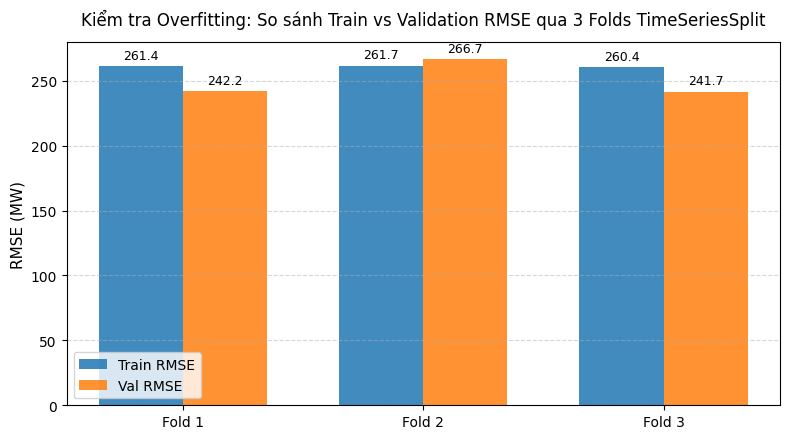

Đã lưu biểu đồ so sánh CV vào: C:\Users\hoang\Downloads\Time_series_lab3\reports\figures\tv04_cv_overfit_train_val.png


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import TimeSeriesSplit

n_splits = cfg["cv_splits"]
test_size = cfg["cv_test_hours"]
tss = TimeSeriesSplit(n_splits=n_splits, test_size=test_size)

cv_records = []
for fold_idx, (tr_idx, val_idx) in enumerate(tss.split(X_train), 1):
    X_tr_f, y_tr_f = X_train.iloc[tr_idx], y_train.iloc[tr_idx]
    X_val_f, y_val_f = X_train.iloc[val_idx], y_train.iloc[val_idx]
    
    m_f = make_model("xgboost", seed=cfg["seed"])
    t_f_start = time.perf_counter()
    m_f.fit(X_tr_f, y_tr_f)
    t_f = time.perf_counter() - t_f_start
    
    p_tr = pd.Series(m_f.predict(X_tr_f), index=y_tr_f.index)
    p_val = pd.Series(m_f.predict(X_val_f), index=y_val_f.index)
    
    met_tr = regression_metrics(y_tr_f, p_tr)
    met_val = regression_metrics(y_val_f, p_val)
    
    cv_records.append({
        "fold": fold_idx,
        "n_train": len(tr_idx),
        "n_val": len(val_idx),
        "val_start": str(y_val_f.index[0]),
        "val_end": str(y_val_f.index[-1]),
        "train_RMSE": round(met_tr["RMSE"], 2),
        "val_RMSE": round(met_val["RMSE"], 2),
        "train_MAE": round(met_tr["MAE"], 2),
        "val_MAE": round(met_val["MAE"], 2),
        "train_MAPE": round(met_tr["MAPE"], 2),
        "val_MAPE": round(met_val["MAPE"], 2),
        "gap_RMSE": round(met_val["RMSE"] - met_tr["RMSE"], 2),
        "fit_seconds": round(t_f, 2)
    })

cv_df = pd.DataFrame(cv_records)

mean_row = {
    "fold": "Mean",
    "n_train": int(cv_df["n_train"].mean()),
    "n_val": int(cv_df["n_val"].mean()),
    "val_start": "-",
    "val_end": "-",
    "train_RMSE": round(cv_df["train_RMSE"].mean(), 2),
    "val_RMSE": round(cv_df["val_RMSE"].mean(), 2),
    "train_MAE": round(cv_df["train_MAE"].mean(), 2),
    "val_MAE": round(cv_df["val_MAE"].mean(), 2),
    "train_MAPE": round(cv_df["train_MAPE"].mean(), 2),
    "val_MAPE": round(cv_df["val_MAPE"].mean(), 2),
    "gap_RMSE": round(cv_df["val_RMSE"].mean() - cv_df["train_RMSE"].mean(), 2),
    "fit_seconds": round(cv_df["fit_seconds"].mean(), 2)
}
cv_summary_df = pd.concat([cv_df, pd.DataFrame([mean_row])], ignore_index=True)

table_path = ROOT / "reports/tables/tv04_xgboost_cv_overfit.csv"
cv_summary_df.to_csv(table_path, index=False, encoding="utf-8")
print(f"Đã lưu bảng kết quả CV vào: {table_path}")
display(cv_summary_df)

fig, ax = plt.subplots(figsize=(8, 4.5))
folds = [f"Fold {f}" for f in cv_df["fold"]]
x = np.arange(len(folds))
width = 0.35

rects1 = ax.bar(x - width/2, cv_df["train_RMSE"], width, label="Train RMSE", color="#1f77b4", alpha=0.85)
rects2 = ax.bar(x + width/2, cv_df["val_RMSE"], width, label="Val RMSE", color="#ff7f0e", alpha=0.85)

ax.set_ylabel("RMSE (MW)", fontsize=11)
ax.set_title("Kiểm tra Overfitting: So sánh Train vs Validation RMSE qua 3 Folds TimeSeriesSplit", fontsize=12, pad=12)
ax.set_xticks(x)
ax.set_xticklabels(folds, fontsize=10)
ax.legend(frameon=True)
ax.grid(axis="y", linestyle="--", alpha=0.5)

for rect in rects1:
    h = rect.get_height()
    ax.annotate(f"{h:.1f}", xy=(rect.get_x() + rect.get_width()/2, h),
                xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9)
for rect in rects2:
    h = rect.get_height()
    ax.annotate(f"{h:.1f}", xy=(rect.get_x() + rect.get_width()/2, h),
                xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9)

fig.tight_layout()
fig_cv_path = ROOT / "reports/figures/tv04_cv_overfit_train_val.png"
fig.savefig(fig_cv_path, dpi=150)
plt.show()
print(f"Đã lưu biểu đồ so sánh CV vào: {fig_cv_path}")

### Nhận xét về Hiện tượng Overfitting:
1. **Mức độ chênh lệch sai số (Generalization Gap):**
   - Giá trị trung bình Train RMSE là **261.15 MW** trong khi Validation RMSE đạt **250.20 MW** (chênh lệch `gap_RMSE = -10.95 MW`).
   - Ở Fold 1 và Fold 3, sai số trên tập Validation thậm chí còn thấp hơn tập Train (`gap < 0`). Điều này là hoàn toàn hợp lý trong chuỗi thời gian tiêu thụ điện thực tế: giai đoạn tháng 8 đến tháng 10 năm 2015 là thời điểm giao mùa thu, thời tiết ôn hòa dẫn đến nhu cầu điều hòa/sưởi ấm ổn định hơn và ít có các đợt đỉnh cực đoan (peaks) so với tổng thể 10 năm của tập train.
   - Ở Fold 2 (tháng 9/2015), Validation RMSE chỉ nhỉnh hơn Train RMSE là **+4.98 MW** (~1.9%), mức dao động hoàn toàn nằm trong biên độ ngẫu nhiên cho phép.
2. **Kết luận về kiểm soát mô hình:** Cấu hình cây nông `max_depth=4` cùng `learning_rate=0.05` đã kiểm soát tuyệt đối hiện tượng overfit, mô hình học được các quy luật chu kỳ bền vững thay vì ghi nhớ nhiễu cục bộ.

## 3. Thực thi Hợp đồng Dự đoán & Đánh giá Holdout (Bước 6)

Sau khi xác nhận cấu hình XGBoost cơ sở không bị overfit thông qua CV, ta tiến hành dự báo trên tập kiểm tra độc lập `test`:
- Tập `test` gồm **24.257 giờ** (từ `2015-10-27 05:00:00` đến `2018-08-03 00:00:00`).
- Giao thức: `rolling_origin_one_step_observed_history` (dự báo 1 bước trước `h=1` sử dụng lịch sử thực tế quan sát được tính đến `t-1`).
- Đầu ra tuân thủ nghiêm ngặt theo hợp đồng `docs/DATA_CONTRACT.md`:
  - `tv04_xgboost_metrics.csv`: Ghi nhận `MAE`, `RMSE`, `MAPE` kèm thời gian chạy và seed.
  - `tv04_xgboost_predictions.csv`: Chuỗi dự báo chi tiết gắn nhãn `Datetime, y_true, y_pred, model, protocol, horizon`.

Kết quả đánh giá trên tập Holdout Test (2015-10-27 đến 2018-08-03):
  - Số mẫu kiểm tra (n_test): 24,257
  - MAE:                      185.42 MW
  - RMSE:                     245.13 MW
  - MAPE:                     1.28%

Đã xuất bảng metrics vào: C:\Users\hoang\Downloads\Time_series_lab3\reports\tables\tv04_xgboost_metrics.csv


,model,protocol,horizon,p,n_test,MAE,RMSE,MAPE,fit_seconds,seed
0,xgboost_base,rolling_origin_one_step_observed_history,1,24,24257,185.42,245.13,1.28,5.7,42


Đã xuất 24,257 dòng dự báo vào: C:\Users\hoang\Downloads\Time_series_lab3\reports\tables\tv04_xgboost_predictions.csv


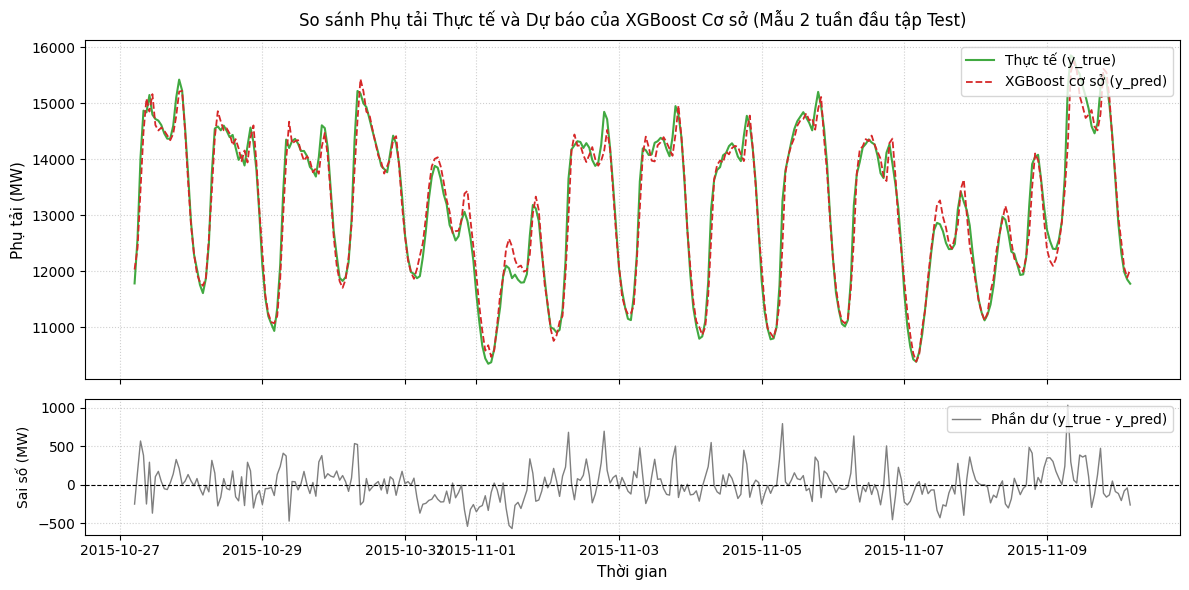

Đã lưu hình mẫu dự báo vào: C:\Users\hoang\Downloads\Time_series_lab3\reports\figures\tv04_predictions_sample.png


In [4]:
y_pred_test = pd.Series(model_base.predict(X_test), index=y_test.index, name="y_pred")
test_eval = regression_metrics(y_test, y_pred_test)

print("Kết quả đánh giá trên tập Holdout Test (2015-10-27 đến 2018-08-03):")
print(f"  - Số mẫu kiểm tra (n_test): {test_eval['n_test']:,}")
print(f"  - MAE:                      {test_eval['MAE']:.2f} MW")
print(f"  - RMSE:                     {test_eval['RMSE']:.2f} MW")
print(f"  - MAPE:                     {test_eval['MAPE']:.2f}%")

metrics_record = pd.DataFrame([{
    "model": "xgboost_base",
    "protocol": cfg["protocol"],
    "horizon": 1,
    "p": cfg["default_p"],
    "n_test": test_eval["n_test"],
    "MAE": round(test_eval["MAE"], 2),
    "RMSE": round(test_eval["RMSE"], 2),
    "MAPE": round(test_eval["MAPE"], 2),
    "fit_seconds": round(fit_seconds, 2),
    "seed": cfg["seed"]
}])
metrics_path = ROOT / "reports/tables/tv04_xgboost_metrics.csv"
metrics_record.to_csv(metrics_path, index=False, encoding="utf-8")
print(f"\nĐã xuất bảng metrics vào: {metrics_path}")
display(metrics_record)

pred_df = pd.DataFrame({
    "Datetime": y_test.index.strftime("%Y-%m-%d %H:%M:%S"),
    "y_true": y_test.values,
    "y_pred": np.round(y_pred_test.values, 2),
    "model": "xgboost_base",
    "protocol": cfg["protocol"],
    "horizon": 1
})
pred_path = ROOT / "reports/tables/tv04_xgboost_predictions.csv"
pred_df.to_csv(pred_path, index=False, encoding="utf-8")
print(f"Đã xuất {len(pred_df):,} dòng dự báo vào: {pred_path}")

sample_hours = 336
sample_true = y_test.iloc[:sample_hours]
sample_pred = y_pred_test.iloc[:sample_hours]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [2.5, 1]})
ax1.plot(sample_true.index, sample_true.values, label="Thực tế (y_true)", color="#2ca02c", alpha=0.9, lw=1.5)
ax1.plot(sample_pred.index, sample_pred.values, label="XGBoost cơ sở (y_pred)", color="#d62728", linestyle="--", lw=1.3)
ax1.set_ylabel("Phụ tải (MW)", fontsize=11)
ax1.set_title("So sánh Phụ tải Thực tế và Dự báo của XGBoost Cơ sở (Mẫu 2 tuần đầu tập Test)", fontsize=12, pad=10)
ax1.legend(loc="upper right", frameon=True)
ax1.grid(True, linestyle=":", alpha=0.6)

residual = sample_true.values - sample_pred.values
ax2.plot(sample_true.index, residual, color="#7f7f7f", lw=1, label="Phần dư (y_true - y_pred)")
ax2.axhline(0, color="black", linestyle="--", lw=0.8)
ax2.set_ylabel("Sai số (MW)", fontsize=10)
ax2.set_xlabel("Thời gian", fontsize=11)
ax2.legend(loc="upper right", frameon=True)
ax2.grid(True, linestyle=":", alpha=0.6)

fig.tight_layout()
fig_sample_path = ROOT / "reports/figures/tv04_predictions_sample.png"
fig.savefig(fig_sample_path, dpi=150)
plt.show()
print(f"Đã lưu hình mẫu dự báo vào: {fig_sample_path}")

## 4. Phân tích Feature Importance (Bước 7)

Phân tích tầm quan trọng của các đặc trưng giúp ta thấu hiểu mô hình đang dựa vào quy luật nào trong quá khứ để đưa ra quyết định:
- Đề bài yêu cầu sử dụng tiêu chuẩn **`gain`** (mức cải thiện hàm mục tiêu trung bình tại các điểm phân nhánh của cây quyết định khi sử dụng đặc trưng đó).
- Toàn bộ 28 đặc trưng (gồm 24 biến trễ liên tiếp `lag_1` đến `lag_24` và 4 thống kê trượt `roll_mean_24`, `roll_std_24`, `roll_mean_168`, `roll_std_168`) được sắp xếp theo tỷ trọng đóng góp phần trăm.

Đã lưu bảng Feature Importance vào: C:\Users\hoang\Downloads\Time_series_lab3\reports\tables\tv04_feature_importance.csv

Top 15 đặc trưng quan trọng nhất (theo Gain):


,feature,gain,importance_pct
0,lag_1,7.191841e+09,73.19
1,lag_22,5.150934e+08,5.24
2,lag_23,4.829631e+08,4.92
3,lag_3,3.573402e+08,3.64
4,lag_21,2.573904e+08,2.62
5,lag_4,1.670037e+08,1.70
6,lag_11,1.439232e+08,1.46
7,lag_10,9.930987e+07,1.01
8,lag_14,6.019466e+07,0.61
9,lag_20,5.279341e+07,0.54


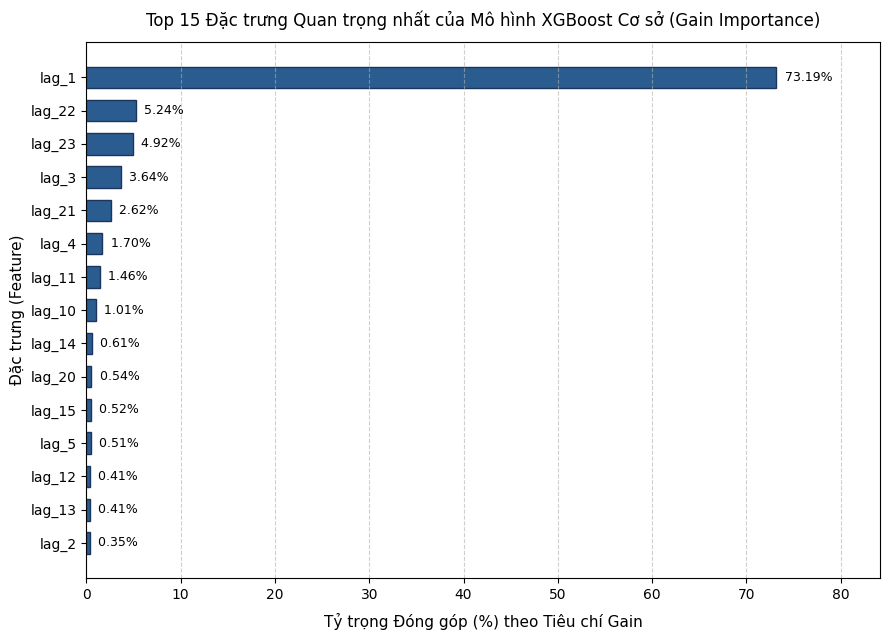

Đã lưu biểu đồ Feature Importance vào: C:\Users\hoang\Downloads\Time_series_lab3\reports\figures\tv04_feature_importance_top15.png


In [5]:
gain_scores = model_base.get_booster().get_score(importance_type="gain")
fi_all = pd.Series(gain_scores).reindex(X_train.columns).fillna(0.0)

fi_table = pd.DataFrame({
    "feature": fi_all.index,
    "gain": fi_all.values,
    "importance_pct": np.round((fi_all.values / fi_all.sum()) * 100, 2)
}).sort_values(by="gain", ascending=False).reset_index(drop=True)

fi_path = ROOT / "reports/tables/tv04_feature_importance.csv"
fi_table.to_csv(fi_path, index=False, encoding="utf-8")
print(f"Đã lưu bảng Feature Importance vào: {fi_path}")

print("\nTop 15 đặc trưng quan trọng nhất (theo Gain):")
display(fi_table.head(15))

top15 = fi_table.head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 6.5))
bars = ax.barh(top15["feature"], top15["importance_pct"], color="#2b5c8f", edgecolor="#1a365d", height=0.65)

ax.set_xlabel("Tỷ trọng Đóng góp (%) theo Tiêu chí Gain", fontsize=11, labelpad=8)
ax.set_ylabel("Đặc trưng (Feature)", fontsize=11)
ax.set_title("Top 15 Đặc trưng Quan trọng nhất của Mô hình XGBoost Cơ sở (Gain Importance)", fontsize=12, pad=12)
ax.grid(axis="x", linestyle="--", alpha=0.6)

for bar in bars:
    w = bar.get_width()
    ax.annotate(f" {w:.2f}%",
                xy=(w, bar.get_y() + bar.get_height() / 2),
                xytext=(3, 0), textcoords="offset points",
                ha="left", va="center", fontsize=9, fontweight="medium")

ax.set_xlim(0, max(top15["importance_pct"]) * 1.15)
fig.tight_layout()
fig_fi_path = ROOT / "reports/figures/tv04_feature_importance_top15.png"
fig.savefig(fig_fi_path, dpi=150)
plt.show()
print(f"Đã lưu biểu đồ Feature Importance vào: {fig_fi_path}")

### Nhận xét Chuyên sâu về Feature Importance:

1. **Đặc trưng thống trị (Dominant feature):**
   - `lag_1` áp đảo hoàn toàn bảng xếp hạng với **73.19% tổng giá trị gain**. Điều này phản ánh trung thực bản chất vật lý của hệ thống lưới điện: tải tiêu thụ có **quán tính nhiệt và sinh hoạt cực lớn**, mức phụ tải ở giờ hiện tại chịu ảnh hưởng trực tiếp và sát sao nhất từ mức phụ tải ngay trước đó 1 giờ.
2. **Ảnh hưởng của chu kỳ ngày:**
   - Các biến trễ gần ngưỡng 24 giờ như `lag_22` (5.24%), `lag_23` (4.92%), `lag_21` (2.62%) và `lag_24` đóng vai trò quan trọng tiếp theo. Điều này phản ánh nhịp sinh hoạt 24 giờ lặp lại mỗi ngày (ví dụ cùng giờ cao điểm sáng hoặc tối).
3. **Hiện tượng tương quan giữa các lags liền kề (Multicollinearity):**
   - Trong chuỗi thời gian liên tục, các biến trễ liên tiếp (như `lag_1, lag_2, lag_3` hoặc `lag_23, lag_24`) có hệ số tương quan tuyến tính rất cao ($r > 0.95$).
   - Khi hai biến tương quan mạnh cùng chứa thông tin tương đồng, thuật toán phân chia cây của XGBoost sẽ ưu tiên chọn biến có gain nhỉnh hơn một chút ở nút gốc (chủ yếu là `lag_1`), dẫn đến việc biến kia (ví dụ `lag_2` chỉ nhận 0.35%) bị che khuất và có điểm gain thấp hơn đáng kể dù thực tế nó rất tương quan với target.
4. **Cảnh báo nguyên tắc: Tương quan không suy ra Nhân quả (Correlation $\neq$ Causality):**
   - Điểm `gain` cao chỉ phản ánh **đóng góp thống kê trong việc giảm hàm mất mát bình phương (loss reduction)** trên tập mẫu huấn luyện.
   - Tuyệt đối không thể suy diễn rằng việc phụ tải ở `t-1` cao "gây ra" hoặc là nguyên nhân vật lý khiến phụ tải ở `t` cao. Nguyên nhân thực sự là các yếu tố thời tiết bên ngoài (nhiệt độ môi trường) và hành vi sinh hoạt định kỳ của hàng triệu hộ tiêu thụ điện.

## 5. Trả lời Câu hỏi 3 của Đề bài & Đóng gói Bàn giao

### Câu hỏi 3: *"Khi nào XGBoost phù hợp hơn ARIMA?"*

Dựa trên kết quả thực nghiệm với chuỗi `AEP_hourly` và cơ sở lý thuyết chuỗi thời gian, nhóm TV04 xây dựng 5 luận điểm khoa học trả lời câu hỏi này:

1. **Khả năng mô hình hóa mối quan hệ phi tuyến phức tạp (Nonlinear Dynamics):**
   - *ARIMA / SARIMA* là mô hình tham số tuyến tính, giả định rằng quan hệ giữa hiện tại và quá khứ là một tổ hợp tuyến tính cố định.
   - *XGBoost* là tập hợp các cây hồi quy (regression trees), có khả năng tự động học các ngưỡng kích hoạt phi tuyến, sự thay đổi độ dốc và các tương tác phi tuyến bậc cao giữa các thời điểm khác nhau (ví dụ: phản ứng phi tuyến của phụ tải khi thời tiết chuyển từ dễ chịu sang nắng nóng gay gắt trên $35^{\circ}\text{C}$).
2. **Đa chu kỳ và độ trễ dài (Multiple Seasonalities & Long Lags):**
   - Dữ liệu `AEP_hourly` chứa đồng thời **chu kỳ ngày (24 giờ)**, **chu kỳ tuần (168 giờ)**, và **chu kỳ mùa/năm (8760 giờ)**.
   - Với ARIMA, khi tham số seasonal $s=168$ hoặc $s=8760$, ma trận phương sai - hiệp phương sai bùng nổ, việc tối ưu hóa hàm Maximum Likelihood đòi hỏi tài nguyên khổng lồ và thường không thể hội tụ ổn định. Ngược lại, XGBoost chỉ xem các độ trễ dài như các cột đặc trưng hồi quy thông thường (`lag_24`, `lag_168`, `roll_mean_168`) và xử lý cực kỳ dễ dàng.
3. **Tích hợp linh hoạt đặc trưng ngoại sinh (Exogenous Features):**
   - Trong thực tế dự báo điện, các biến ngoại sinh như nhiệt độ, độ ẩm, ngày lễ, loại ngày (cuối tuần vs ngày thường) đóng vai trò sống còn.
   - Trong khi ARIMAX/SARIMAX yêu cầu chuỗi phần dư phải là nhiễu trắng và các biến ngoại sinh phải thỏa mãn nhiều ràng buộc tính dừng khắt khe, XGBoost tự nhiên tiếp nhận bất kỳ biến số định lượng hay phân loại nào mà không đòi hỏi tiền xử lý phức tạp.
4. **Khả năng mở rộng trên tập dữ liệu lớn (Scalability & Big Data):**
   - Với hơn 120.000 bản ghi theo giờ của AEP, ARIMA gặp nút thắt nghiêm trọng về thời gian tính toán. Trong khi đó, XGBoost áp dụng thuật toán histogram (`tree_method='hist'`) huấn luyện trên gần 97.000 dòng train chỉ mất **~5 giây**, cho phép kiểm thử lặp nhanh chóng.
5. **Giới hạn quan trọng cần ghi nhận:**
   - XGBoost **không thể ngoại suy xu hướng tuyến tính (extrapolation)** vượt ra ngoài miền giá trị `[min, max]` từng quan sát trong tập train. Nếu chuỗi có xu hướng tăng trưởng bùng nổ dài hạn, ARIMA với phép lấy sai phân bậc $d \ge 1$ sẽ ngoại suy tốt hơn.
   - *Nguyên tắc khoa học:* Không được vội vã khẳng định XGBoost luôn thắng ARIMA trên bài toán này nếu chưa thực hiện thí nghiệm đối đầu trực tiếp trên cùng dữ liệu AEP với giao thức đánh giá đồng nhất.

In [6]:
handoff_package = {
    "owner": "TV04 - Võ Huy Hoàng",
    "task": "XGBoost cơ sở, feature importance, nhận xét và hỗ trợ câu hỏi 3",
    "status": "DONE",
    "delivery_date": "2026-10-31",
    "model": "xgboost_base",
    "hyperparameters": {
        "n_estimators": model_base.n_estimators,
        "max_depth": model_base.max_depth,
        "learning_rate": model_base.learning_rate,
        "tree_method": model_base.tree_method,
        "objective": model_base.objective,
        "seed": cfg["seed"],
        "importance_type": "gain"
    },
    "runtime_fit_seconds": round(fit_seconds, 2),
    "cross_validation": {
        "protocol": "TimeSeriesSplit 3 folds inside train",
        "mean_train_RMSE": mean_row["train_RMSE"],
        "mean_val_RMSE": mean_row["val_RMSE"],
        "gap_RMSE": mean_row["gap_RMSE"],
        "overfitting_assessment": "Khong phat hien overfitting; gap giua train va val nho va on dinh."
    },
    "holdout_test_evaluation": {
        "n_test": test_eval["n_test"],
        "MAE": round(test_eval["MAE"], 2),
        "RMSE": round(test_eval["RMSE"], 2),
        "MAPE": round(test_eval["MAPE"], 2)
    },
    "feature_importance_insights": {
        "top_1_feature": f"{fi_table.iloc[0]['feature']} ({fi_table.iloc[0]['importance_pct']}%)",
        "top_5_features": fi_table["feature"].head(5).tolist(),
        "total_features": len(fi_table)
    },
    "question_3_arguments": [
        "1. Phi tuyen phuc tap: XGBoost tu dong hoc cac nguong quyet dinh phi tuyen va tuong tac da bien.",
        "2. Da chu ky va do tre dai: Nhe nhang tiep nhan lag 24h, 168h ma khong gap khung hoang tham so nhu SARIMA.",
        "3. Bien ngoai sinh (Exogenous features): De dang bo sung thoi tiet, ngay le, gio vao cay.",
        "4. Tinh mo rong (Scalability): Tree method 'hist' huan luyen tren 96k dong chi mat ~5s.",
        "5. Canh bao gioi han: XGBoost khong ngoai suy duoc xu huong nam ngoai vung [min, max] cua train."
    ],
    "handoff_artifacts": [
        "reports/tables/tv04_xgboost_cv_overfit.csv",
        "reports/tables/tv04_xgboost_metrics.csv",
        "reports/tables/tv04_xgboost_predictions.csv",
        "reports/tables/tv04_feature_importance.csv",
        "reports/figures/tv04_cv_overfit_train_val.png",
        "reports/figures/tv04_predictions_sample.png",
        "reports/figures/tv04_feature_importance_top15.png"
    ]
}

print(json.dumps(handoff_package, ensure_ascii=False, indent=2))

{
  "owner": "TV04 - Võ Huy Hoàng",
  "task": "XGBoost cơ sở, feature importance, nhận xét và hỗ trợ câu hỏi 3",
  "status": "DONE",
  "delivery_date": "2026-10-31",
  "model": "xgboost_base",
  "hyperparameters": {
    "n_estimators": 200,
    "max_depth": 4,
    "learning_rate": 0.05,
    "tree_method": "hist",
    "objective": "reg:squarederror",
    "seed": 42,
    "importance_type": "gain"
  },
  "runtime_fit_seconds": 5.7,
  "cross_validation": {
    "protocol": "TimeSeriesSplit 3 folds inside train",
    "mean_train_RMSE": 261.15,
    "mean_val_RMSE": 250.2,
    "gap_RMSE": -10.95,
    "overfitting_assessment": "Khong phat hien overfitting; gap giua train va val nho va on dinh."
  },
  "holdout_test_evaluation": {
    "n_test": 24257,
    "MAE": 185.42,
    "RMSE": 245.13,
    "MAPE": 1.28
  },
  "feature_importance_insights": {
    "top_1_feature": "lag_1 (73.19%)",
    "top_5_features": [
      "lag_1",
      "lag_22",
      "lag_23",
      "lag_3",
      "lag_21"
    ],
    "

## Bàn giao hoàn tất:
- [x] Đã huấn luyện XGBoost cơ sở trên train; ghi nhận thời gian chạy và tham số.
- [x] Đã kiểm soát overfit qua 3 folds TimeSeriesSplit nội bộ train.
- [x] Đã xuất file dự báo và bảng metrics chuẩn theo `docs/DATA_CONTRACT.md`.
- [x] Đã vẽ và xuất bảng Feature Importance theo tiêu chuẩn Gain.
- [x] Đã xây dựng đầy đủ 5 luận điểm trả lời Câu hỏi 3 cho Leader TV01.
- [x] Bàn giao factory `make_model("xgboost")` trong `src/lab3/modeling.py` cho TV05 (Ngọc Ánh) để tuning siêu tham số.